
# Heart Disease Prediction Using Logistic Regression

## 1. Introduction
Heart disease is one of the major health concerns worldwide. Early identification of potential risk factors can help support timely medical screening and preventive care.

## 2. Business Objective
Build a classification model that predicts the presence of heart disease from clinical indicators, supporting early screening and
preventive care.

## 3. Problem Statement
A hospital wants a first-pass screening model that flags patients at higher risk of heart disease based on clinical measurements
such as blood pressure, cholesterol, and heart rate.

## 4. Why this matters?
Healthcare classification problems require extra care with evaluation (a missed positive case has real consequences), making
this project a strong lesson in why metrics like recall matter as much as accuracy.

## 5. Machine Learning Approach
- Learning Type: Supervised Learning
- Problem Type: Binary Classification
- Algorithm: Logistic Regression
- Evaluation: Accuracy, Precision, Recall, F1-score and ROC-AUC

## 6. Importing Libraries
- Pandas, numpy, matplotlib, scikit-learn, seaborn

In [54]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)

#url = "https://raw.githubusercontent.com/GehadGad/Heart-disease-dataset/main/heart.csv"

df = pd.read_csv('heart.csv')
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


 Loaded the data and now understanding the data

 #### Understanding Data:
- Any duplicates
- Missing Values
- Required Columns present
- Appropriate data types

In [55]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1025, 14)


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [57]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [58]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [67]:
print("Unique values in ca:")
print(df['ca'].value_counts().sort_index())

print("\nUnique values in thal:")
print(df['thal'].value_counts().sort_index())
print("\nOutput column: ")
print("Unique values in target:")
print(df['target'].value_counts())

Unique values in ca:
ca
0    578
1    226
2    134
3     69
4     18
Name: count, dtype: int64

Unique values in thal:
thal
0      7
1     64
2    544
3    410
Name: count, dtype: int64

Output column: 
Unique values in target:
target
1    526
0    499
Name: count, dtype: int64


#### Handling Missing Values and Duplicate records

- There were no missing values found in the dataset.
- Duplicate records were identified in the original dataset.

In [60]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Records: 723


In [61]:
print("Shape of original dataset:", df.shape)
df_clean = df.drop_duplicates()

print("After removing duplicates:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Shape of original dataset: (1025, 14)
After removing duplicates: (302, 14)
Remaining duplicates: 0


In [62]:
print("Missing values:")
print(df_clean.isnull().sum())

print("\nTarget distribution:")
print(df_clean['target'].value_counts())

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


#### Data Cleaning Results
- Missing values: None were found.
- Duplicates Removed: 302 records remain.
(302 rows are unique records, not necessarily 302 verified individual patients.)
- Target distribution: Relatively balanced, although there are slightly more positive cases.

## Categorical Feature Inspection

The categorical features were examined to understand their unique values and frequency distributions. This helped identify the different categories present in the dataset and verify their consistency before feature engineering.

In [65]:
print("Missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:", df_clean.duplicated().sum())

print("\nTarget:")
print(df_clean['target'].value_counts())

print("\nUnique gender values:")
print(df_clean['sex'].value_counts())

print("\nUnique cp values:")
print(df_clean['cp'].value_counts())

print("\nUnique fbs values:")
print(df_clean['fbs'].value_counts())

print("\nUnique restecg values:")
print(df_clean['restecg'].value_counts())

print("\nUnique exang values:")
print(df_clean['exang'].value_counts())

print("\nUnique slope values:")
print(df_clean['slope'].value_counts())

print("\nUnique thal values:")
print(df_clean['thal'].value_counts())

print("\nUnique ca values:")
print(df_clean['ca'].value_counts())

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate records: 0

Target:
target
1    164
0    138
Name: count, dtype: int64

Unique gender values:
sex
1    206
0     96
Name: count, dtype: int64

Unique cp values:
cp
0    143
2     86
1     50
3     23
Name: count, dtype: int64

Unique fbs values:
fbs
0    257
1     45
Name: count, dtype: int64

Unique restecg values:
restecg
1    151
0    147
2      4
Name: count, dtype: int64

Unique exang values:
exang
0    203
1     99
Name: count, dtype: int64

Unique slope values:
slope
2    141
1    140
0     21
Name: count, dtype: int64

Unique thal values:
thal
2    165
3    117
1     18
0      2
Name: count, dtype: int64

Unique ca values:
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64


### Exploratory Data Analysis (EDA)
Exploratory Data Analysis is performed to understand the dataset, identify patterns and examine relationships between different features and the target variable before building the machine learning model.

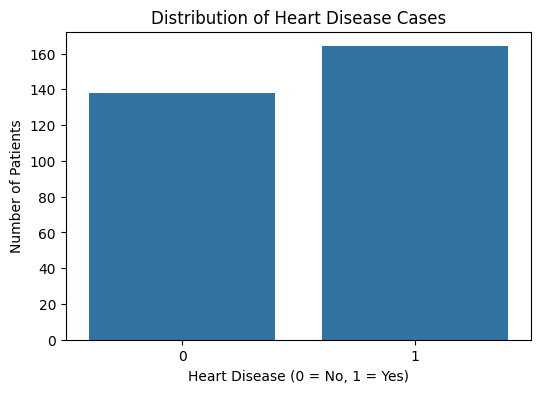

In [69]:
#Heart disease patients and non-patients
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x='target')

plt.title('Distribution of Heart Disease Cases')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')

plt.show()

### Target Distribution

The dataset contains 164 records with heart disease and 138 records without heart disease. The target classes are relatively balanced, with a slight majority of positive cases.

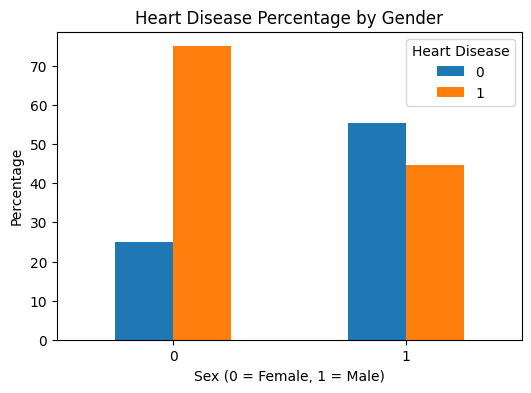

In [71]:
gender_data = pd.crosstab(
    df_clean['sex'],
    df_clean['target'],
    normalize='index'
) * 100

gender_data.plot(kind='bar', figsize=(6, 4))

plt.title('Heart Disease Percentage by Gender')
plt.xlabel('Sex (0 = Female, 1 = Male)')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.legend(title='Heart Disease')

plt.show()

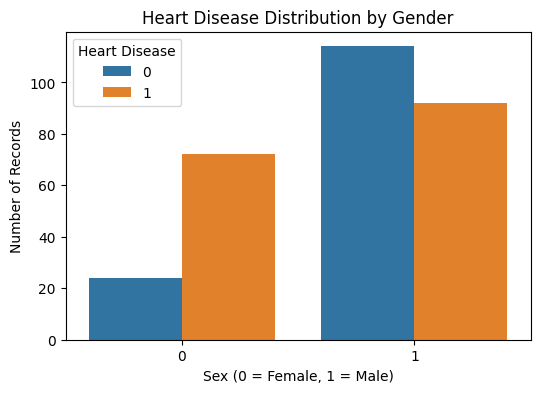

In [70]:
#Gender distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x='sex', hue='target')

plt.title('Heart Disease Distribution by Gender')
plt.xlabel('Sex (0 = Female, 1 = Male)')
plt.ylabel('Number of Records')

plt.legend(title='Heart Disease')
plt.show()

### Heart Disease Distribution by Gender

The female group has more heart disease-positive records, whereas the male group has more heart disease-negative records. This indicates a difference in the distribution of heart disease across the two gender groups in the dataset.
calculate the percentage within each gender group:
- Female: \(72/96 * 100 = 75\%\)
- Male: \(92/206 * 100 =  44.7\%\)

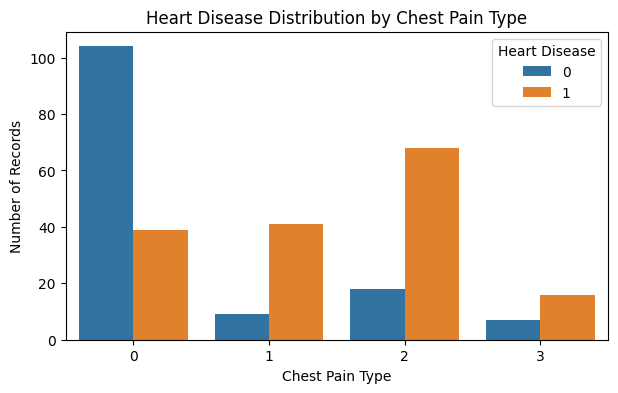

In [72]:
#Chest pain as a factor of heart disease
plt.figure(figsize=(7, 4))

sns.countplot(data=df_clean, x='cp', hue='target')

plt.title('Heart Disease Distribution by Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Records')
plt.legend(title='Heart Disease')

plt.show()

###Interpretation
- Type 0: Most records indicate no heart disease.
- Type 1: More records indicate heart disease than no disease.
- Type 2: Heart disease-positive records are considerably higher.
- Type 3: More records indicate heart disease, although the total number of records is small.

### Heart Disease Distribution by Chest Pain Type

Chest pain type 0 has more negative cases, whereas types 1, 2 and 3 have more positive cases. This suggests that chest pain type may have a useful association with the target variable.

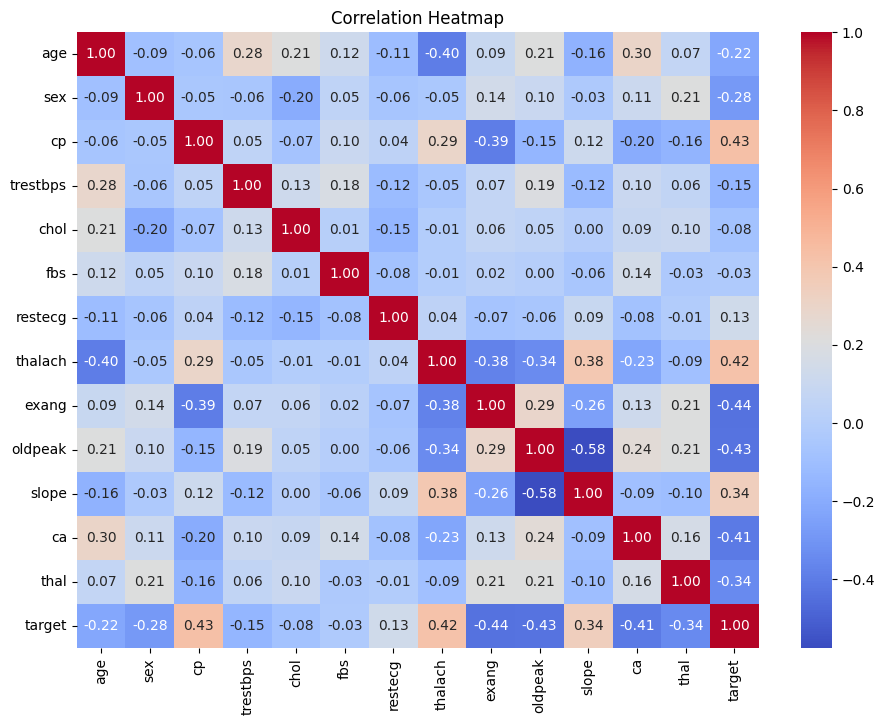

In [73]:
#Heatmap to understand correlation between different features
plt.figure(figsize=(11, 8))

sns.heatmap(
    df_clean.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### Correlation Analysis

The correlation heatmap shows that chest pain type, maximum heart rate, exercise-induced angina, oldpeak and number of major vessels have relatively stronger correlations with the target. Cholesterol and fasting blood sugar show comparatively weak linear correlations. These observations will help us understand feature relationships before model building.

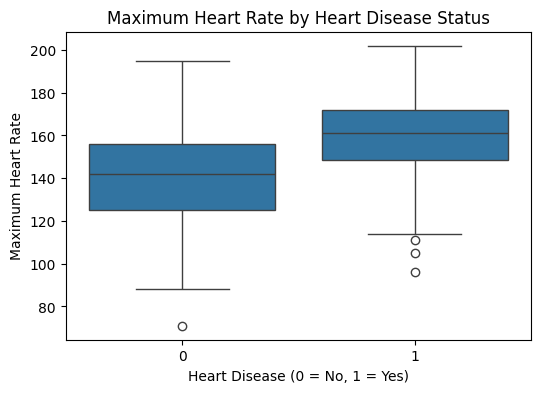

In [74]:
#Maximum heart rate analysis
plt.figure(figsize=(6, 4))

sns.boxplot(data=df_clean, x='target', y='thalach')

plt.title('Maximum Heart Rate by Heart Disease Status')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Maximum Heart Rate')

plt.show()

#### Maximum Heart Rate Analysis

The boxplot shows that the median maximum heart rate is higher in the heart disease-positive group than in the negative group. This suggests that maximum heart rate may provide useful information for classification.

###Feature Engineering

Feature engineering involves preparing the dataset for machine learning by encoding categorical variables and scaling numerical features.

In [81]:
X = df_clean.drop('target', axis=1)
y = df_clean['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (302, 13)
Target shape: (302,)


In [82]:
#one-hot encoding
X = pd.get_dummies(
    X,
    columns=['cp', 'restecg', 'slope', 'thal'],
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", X.shape)
display(X.head())

Shape after encoding: (302, 19)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1,cp_2,cp_3,restecg_1,restecg_2,slope_1,slope_2,thal_1,thal_2,thal_3
0,52,1,125,212,0,168,0,1.0,2,0,0,0,1,0,0,1,0,0,1
1,53,1,140,203,1,155,1,3.1,0,0,0,0,0,0,0,0,0,0,1
2,70,1,145,174,0,125,1,2.6,0,0,0,0,1,0,0,0,0,0,1
3,61,1,148,203,0,161,0,0.0,1,0,0,0,1,0,0,1,0,0,1
4,62,0,138,294,1,106,0,1.9,3,0,0,0,1,0,1,0,0,1,0


In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,#80-20
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (241, 19)
Testing data: (61, 19)


In [87]:
numerical_columns = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

scaler = StandardScaler()

X_train[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)
#print(X_train[numerical_columns])
print("Feature scaling completed!")

Feature scaling completed!


## Model Building – Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for binary classification. It estimates the probability of an observation belonging to a particular class and classifies it based on a decision threshold.

In [88]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Model trained successfully!")

Model trained successfully!


In [89]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8524590163934426
Precision: 0.875
Recall: 0.8484848484848485
F1 Score: 0.8615384615384616


### Initial Model Evaluation

The Logistic Regression model achieved an accuracy of 85.25%, precision of 87.50%, recall of 84.85% and F1-score of 86.15%. These results indicate reasonably good classification performance, with a balanced ability to identify positive and negative cases.

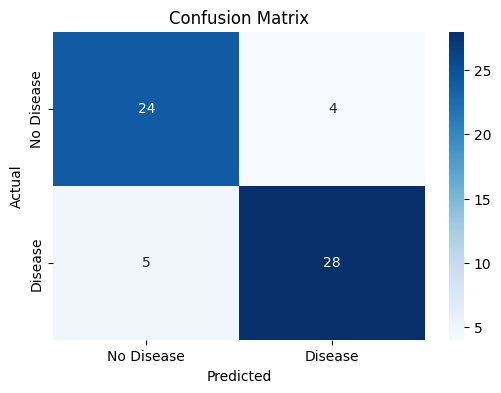

In [90]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

ROC-AUC Score: 0.8982683982683983


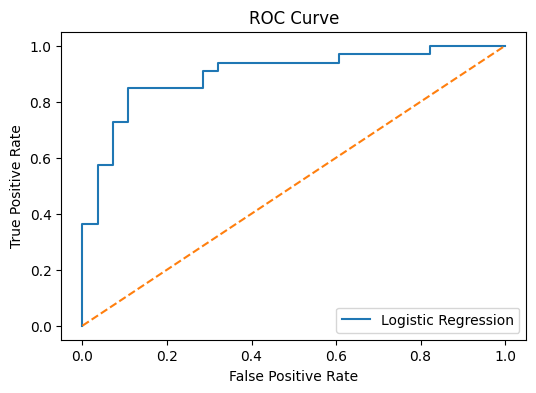

In [91]:
y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend()
plt.show()

### ROC Curve and AUC Analysis

The model achieved a ROC-AUC score of 0.8983, indicating good ability to distinguish between patients with and without heart disease. The ROC curve remains above the random-classification baseline, demonstrating better-than-random classification performance.

In [92]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
})

coefficients['Importance'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Importance',
    ascending=False
)

print(coefficients)

      Feature  Coefficient  Importance
10       cp_2     1.519340    1.519340
11       cp_3     1.316186    1.316186
1         sex    -1.194533    1.194533
6       exang    -0.928756    0.928756
8          ca    -0.761777    0.761777
18     thal_3    -0.703354    0.703354
5     thalach     0.676867    0.676867
9        cp_1     0.616150    0.616150
17     thal_2     0.595710    0.595710
12  restecg_1     0.455665    0.455665
16     thal_1     0.356840    0.356840
14    slope_1    -0.349760    0.349760
7     oldpeak    -0.321004    0.321004
15    slope_2     0.266685    0.266685
3        chol    -0.251699    0.251699
2    trestbps    -0.249495    0.249495
0         age     0.137818    0.137818
13  restecg_2    -0.047742    0.047742
4         fbs     0.046390    0.046390


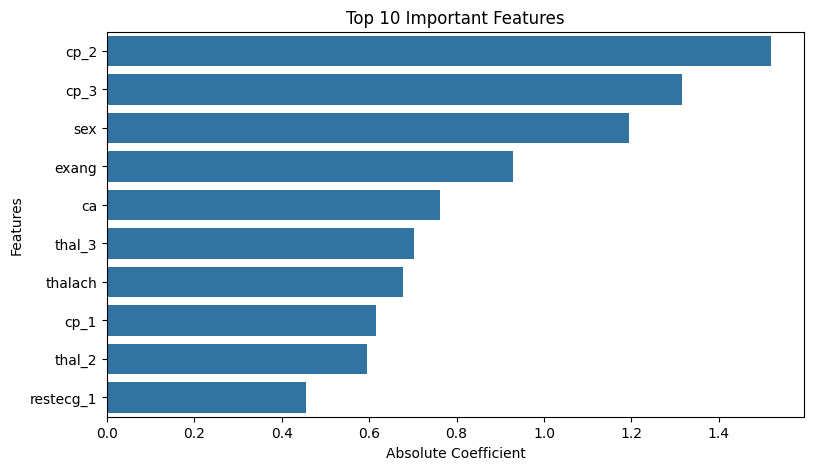

In [93]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=coefficients.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features')
plt.xlabel('Absolute Coefficient')
plt.ylabel('Features')

plt.show()

### Feature Importance Analysis

The Logistic Regression coefficients indicate that chest pain categories (`cp_2` and `cp_3`), sex, exercise-induced angina (`exang`) and number of major vessels (`ca`) are among the most influential features in the model. Chest pain type shows particularly high coefficient magnitudes, suggesting its importance in classification.

In [94]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84        28
           1       0.88      0.85      0.86        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



## Conclusion

A Logistic Regression model was developed to predict the presence of heart disease using patient characteristics and clinical measurements. The model achieved 85.25% accuracy and a ROC-AUC score of 0.8983, showing good classification performance on the test dataset.

Chest pain type, sex, exercise-induced angina and other clinical indicators contributed to the model's predictions.